## Fenwick Tree(Binary Indexed Tree)(フェニック木)

参考:[Qiita](https://qiita.com/iorn121/items/d3c24c4d4b014531b782)

区間和の更新が高速に行える木構造について解説します。

### BITについて

BITはセグメント木の一種で、通常の配列と累積和配列がもつオーダーの遅い部分を補うための木構造で、更新も区間和の計算も$O(log(N))$で実行することができます。

|操作|通常の配列|累積和配列|BIT|
| ------------ | ---------------- | ---------------- | ---------------- |
|更新|O(1) → A[2] = 10|`O(N)` → 再計算|O(logN)|
|区間和|`O(N)` → sum(A[0:3])|O(1) → ac[3]-ac[0]|O(logN)|

長さNの配列で実装できる点が特異であるといえます。

In [ ]:
A = list(range(1,9))
print(A)

BIT = [0]*(8+1)

BIT[1]=1 # Aの 1番目の値
BIT[2]=1+2 # Aの 1,2番目の和
BIT[3]=3 # Aの 3番目の数
BIT[4]=1+2+3+4 # Aの 1,2,3,4番目の和
BIT[5]=5 # Aの　5番目の数
BIT[6]=5+6 # Aの 5,6番目の和
BIT[7]=7 # Aの 7番目の和
BIT[8]=1+2+3+4+5+6+7+8 # Aの 1,2,3,4,5,6,7,8番目の和

print(BIT)

[1, 2, 3, 4, 5, 6, 7, 8]
[0, 1, 3, 3, 10, 5, 11, 7, 36]


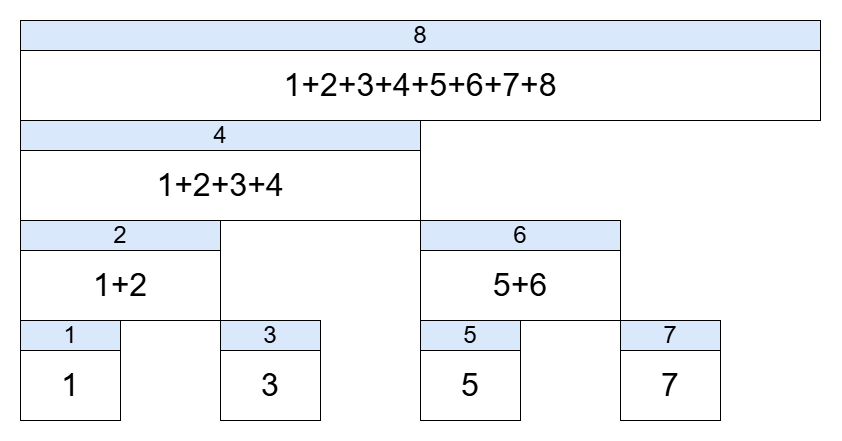

### 区間和の計算

A[3]-A[7]の和を求めるには、通常と同じように、A[0]-A[7] - A[0]-A[2]を計算します。  
ここでA[0]-A[7]を求めるときに、ビット演算を用います。

7=111(2)について、右端の1を0にする操作を繰り返します。  
111(2) -> 110(2) -> 100(2) -> 000(2)  
十進数では 7 -> 6 -> 4 -> 0 です。  
この値をインデックスとして足し合わせると、累積和を求めることができます。  


In [ ]:
ac7 = BIT[7] + BIT[6] + BIT[4] + BIT[0] #最悪O(log(n))
print(ac7)
#BIT[7]=7 BIT[6]=5+6 BIT[4] = 1+2+3+4 BIT[0]=0

28


同様にA[0]-A[2]について求めれば、A[3]-A[7]を求めることができます。

In [ ]:
ac2 = BIT[2] + BIT[0] # 10 -> 00
ac3_7 = ac7 - ac2
print(ac3_7)

25


区間和の計算に必要なオーダーは累積和の計算が２回で高々O(log(n))であることがわかります。

### 値の更新

A[5]に6を足す操作について考えましょう。  
まず5を二進数で表すと、101(2)となります。
ここで右端の1に1を足す操作を繰り返し、N=8を超える前にやめます。  
101(2) -> 110(2) -> 1000(2) -/>  
十進数では5 -> 6 -> 8 です。  
これらの値をインデックスとして6を足していくことで値の更新ができます。

In [ ]:
#A[5]が入ってる要素が参照できる
BIT1 = BIT.copy() #BITの変更を防ぐ用
BIT1[5]+=6 # BIT[5] = 5   +6
BIT1[6]+=6 # BIT[6] = 5+6   +6
BIT1[8]+=6 # BIT[8] = 1+2+3+4+5+6+7+8   +6
print(BIT1)

[0, 1, 3, 3, 10, 11, 17, 7, 42]


要素の更新のオーダーも高々O(log(N))であることがわかります。

### クラスでの実装

クラスを用いると以下のように実装することができます。

In [ ]:
class BIT:
    # 長さN+1の配列を初期化
    def __init__(self, N):
        self.size = N
        self.bit = [0]*(N+1)

    # i番目までの和を求める
    def sum(self, i):
        res = 0
        while i > 0: # bit[0]=0なので計算しない
            res += self.bit[i] # フェニック木のi番目の値を加算
            i -= -i & i # 最も右にある1の桁を0にする
        return res

    # i番目の値にxを足して更新する
    def add(self, i, x):
        while i <= self.size: # iがNを超えないように制限
            self.bit[i] += x # フェニック木のi番目にxを足して更新
            i += -i & i # 最も右にある1の桁に1を足す


### ライブラリでの実装

AtCoder Library(ACL)にはBITのライブラリが存在します。  
こちらは0-indexedで設計されているため、bit[0]から値を入れる必要があることに注意してください。

In [ ]:
from atcoder.fenwicktree import FenwickTree
N = 8
bit = FenwickTree(N)
for i in range(N):
    bit.add(i,i+1)
print(bit.sum(2,6+1)) # 前例の3~7
bit.add(4,6) # 前例の5番目に6を足す操作
print(bit.data)

25
[1, 3, 3, 10, 11, 17, 7, 42]


#### 操作一覧

|操作|操作内容|計算量|
|---|---|---|
|FenwickTree.add(i, x)|i 番目の要素に x を加算|O(logN)|
|FenwickTree.sum(l, r)|区間和 [l, r)の計算|O(logN)|
|FenwickTree.data|現在のBIT配列を返す|O(N)|